# EEG Signal Processing Lab — 01 · Loading & Raw Inspection

**Version 0.2 — first reproducible analysis notebook.**

This notebook loads a small, well-defined slice of the public **PhysioNet EEG
Motor Movement/Imagery Dataset (EEGMMIDB) v1.0.0** with
[MNE-Python](https://mne.tools/), confirms its basic facts (channels, sampling
rate, duration, events), and produces a first set of inspection figures.

## Scope

This is a **signal-inspection** notebook, corresponding to Stages 2–3 of the
project plan (dataset loading and raw inspection):

**In scope (here):**
- Load selected subjects/runs via MNE's EEGBCI helper.
- Confirm channel names/count, sampling rate, and per-run duration.
- Map the annotation codes **T0 / T1 / T2** to conditions *by run type*.
- Summarize the event/condition distribution.
- Generate basic, well-labeled inspection figures.

**Out of scope (deferred to later versions):**
- Filtering, re-referencing, and ICA (conservative preprocessing → v0.3).
- Epoching and PSD / frequency analysis (→ v0.3 → v1.0).
- **Any classifier, machine learning, or deep learning.**

> ⚠️ This is an educational, exploratory signal-processing project. It is **not
> a clinical or diagnostic tool and makes no medical claims.** All observations
> below are descriptive and tied strictly to the selected subjects and runs.

## Dataset and subset rationale

| Property | Value |
| --- | --- |
| Name | EEG Motor Movement/Imagery Dataset (EEGMMIDB) |
| Version | 1.0.0 |
| Source | https://physionet.org/content/eegmmidb/1.0.0/ |
| DOI | https://doi.org/10.13026/C28G6P |
| Channels | 64 EEG |
| Sampling rate | 160 Hz |
| Format | EDF+ (with annotation channel) |
| License | Open Data Commons Attribution License v1.0 (ODC-By) |

The dataset is accessed through MNE-Python's
[`mne.datasets.eegbci.load_data`](https://mne.tools/dev/generated/mne.datasets.eegbci.load_data.html)
helper, which downloads only the requested files. Downloads are written to the
repository's **git-ignored** `data/raw/` directory and are **never committed**.

### Version 1 analysis slice

- **Subjects:** 1, 2, 3
- **Runs:** 1 (eyes-open baseline), 2 (eyes-closed baseline), 4, 8, 12
  (motor imagery, left vs right hand)

**Why this subset:** it is small enough to download and run quickly, includes
both baseline conditions (for a future eyes-open vs eyes-closed comparison), and
includes three motor-imagery left/right-hand runs that are directly relevant to
brain–computer interface (BCI) work. Motor-*execution* runs and hands/feet runs
are deliberately excluded to keep this first release focused.

## Run-aware event mapping (the critical detail)

The EDF annotation channel uses three codes — **T0**, **T1**, **T2** — but their
meaning is **not globally fixed**. `T0` is always rest; the meaning of `T1`/`T2`
**depends on the run type**. This notebook maps codes using the *run number*,
never the code alone (the single most common failure mode for this dataset).

| Code | Baseline run 1 (eyes open) | Baseline run 2 (eyes closed) | L/R-hand imagery runs 4, 8, 12 |
| --- | --- | --- | --- |
| **T0** | rest (eyes open) | rest (eyes closed) | rest |
| **T1** | — | — | left fist (imagined) |
| **T2** | — | — | right fist (imagined) |

The baseline runs contain a single continuous rest annotation (`T0` only). The
mapping is implemented in `eeg_lab.config.map_events_by_run` and re-exported via
`eeg_lab.preprocessing.map_events_by_run`.

In [1]:
# Standard scientific stack + the project package (installed editable as `eeg_lab`).
from itertools import product

import matplotlib.pyplot as plt
import mne
import pandas as pd

from eeg_lab import config, data, preprocessing, visualization

# Quiet MNE's per-call logging; we report the facts we care about explicitly.
mne.set_log_level("WARNING")
pd.set_option("display.max_rows", 40)

SUBJECTS = config.SUBJECTS
RUNS = config.RUNS
FIGURES_DIR = config.FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"eeg_lab version : {__import__('eeg_lab').__version__}")
print(f"MNE-Python      : {mne.__version__}")
print(f"Subjects        : {SUBJECTS}")
print(f"Runs            : {RUNS}")
print(f"Raw data dir    : {config.RAW_DATA_PATH}  (git-ignored)")
print(f"Figures dir     : {FIGURES_DIR}")

eeg_lab version : 1.0.0
MNE-Python      : 1.12.1
Subjects        : (1, 2, 3)
Runs            : (1, 2, 4, 8, 12)
Raw data dir    : /home/jevrton/Development/eeg-signal-processing-lab/data/raw  (git-ignored)
Figures dir     : /home/jevrton/Development/eeg-signal-processing-lab/figures


## 1 · Load the selected recordings

`eeg_lab.data.load_raw` downloads any missing EDF files into `data/raw/`, reads
them with MNE, normalizes the EEGBCI channel names with
`mne.datasets.eegbci.standardize` (this fixes quirks such as trailing dots, e.g.
`"Fcz."` → `"FCz"`), and concatenates runs when several are requested.

The first run of this cell downloads ~15 small EDF files (a few MB total); later
runs reuse the local cache.

In [2]:
# Build a per-(subject, run) metadata table. preload=False is enough for header
# facts and annotations, and keeps this quick.
subject_runs = list(product(SUBJECTS, RUNS))
meta_table = data.build_metadata_table(subject_runs)
meta_table

,subject,run,role,n_channels,n_eeg_channels,sfreq_hz,duration_s,n_annotations
0,1,1,"Baseline, eyes open",64,64,160.0,60.99,1
1,1,2,"Baseline, eyes closed",64,64,160.0,60.99,1
2,1,4,"Motor imagery, left vs right hand",64,64,160.0,124.99,30
3,1,8,"Motor imagery, left vs right hand",64,64,160.0,124.99,30
4,1,12,"Motor imagery, left vs right hand",64,64,160.0,124.99,30
5,2,1,"Baseline, eyes open",64,64,160.0,60.99,1
6,2,2,"Baseline, eyes closed",64,64,160.0,60.99,1
7,2,4,"Motor imagery, left vs right hand",64,64,160.0,122.99,30
8,2,8,"Motor imagery, left vs right hand",64,64,160.0,122.99,30
9,2,12,"Motor imagery, left vs right hand",64,64,160.0,122.99,30


## 2 · Confirm channels, sampling rate, and duration

We explicitly verify the dataset facts against expectations (64 EEG channels,
160 Hz) rather than assuming them, and report the per-run recording durations.

In [3]:
n_eeg_unique = sorted(meta_table["n_eeg_channels"].unique())
sfreq_unique = sorted(meta_table["sfreq_hz"].unique())

print(f"EEG channel counts across all runs : {n_eeg_unique}  (expected [{config.EXPECTED_N_EEG_CHANNELS}])")
print(f"Sampling rates across all runs (Hz): {sfreq_unique}  (expected [{config.EXPECTED_SFREQ_HZ}])")

assert n_eeg_unique == [config.EXPECTED_N_EEG_CHANNELS], "Unexpected EEG channel count"
assert sfreq_unique == [config.EXPECTED_SFREQ_HZ], "Unexpected sampling rate"

# Duration summary per run role.
dur = (
    meta_table.groupby(["run", "role"])["duration_s"]
    .agg(["min", "max", "mean"])
    .round(2)
    .reset_index()
    .rename(columns={"min": "dur_min_s", "max": "dur_max_s", "mean": "dur_mean_s"})
)
print("\nPer-run recording duration (seconds), across subjects 1–3:")
dur

EEG channel counts across all runs : [np.int64(64)]  (expected [64])
Sampling rates across all runs (Hz): [np.float64(160.0)]  (expected [160.0])

Per-run recording duration (seconds), across subjects 1–3:


,run,role,dur_min_s,dur_max_s,dur_mean_s
0,1,"Baseline, eyes open",60.99,60.99,60.99
1,2,"Baseline, eyes closed",60.99,60.99,60.99
2,4,"Motor imagery, left vs right hand",122.99,124.99,124.32
3,8,"Motor imagery, left vs right hand",122.99,124.99,124.32
4,12,"Motor imagery, left vs right hand",122.99,124.99,124.32


In [4]:
# Inspect the channel names of a representative recording (subject 1, run 1).
raw_demo = data.load_raw(1, [1])
preprocessing.apply_montage(raw_demo)

print(f"Total channels : {raw_demo.info['nchan']}")
print(f"First 12 names : {raw_demo.ch_names[:12]}")
print(f"Last 6 names   : {raw_demo.ch_names[-6:]}")
print(f"Sampling rate  : {raw_demo.info['sfreq']} Hz")
print(f"Duration       : {raw_demo.times[-1]:.2f} s")

Total channels : 64
First 12 names : ['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2']
Last 6 names   : ['PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']
Sampling rate  : 160.0 Hz
Duration       : 60.99 s


## 3 · Raw signal preview

Below is a short, multi-channel slice of the **raw** signal (no filtering, no
re-referencing). Traces are offset vertically for legibility and shown in
microvolts (µV). We preview a motor-imagery run (subject 1, run 4).

**Descriptive notes (not clinical):** the traces show typical continuous EEG —
fluctuations on the order of tens of microvolts with no obviously flat or
railed channels in this window. Slow drifts and occasional larger deflections
(plausibly eye or movement related) are visible and are exactly the kind of
artifact that the conservative preprocessing stage (v0.3) will address. No
clinical or diagnostic meaning is attached to these traces.

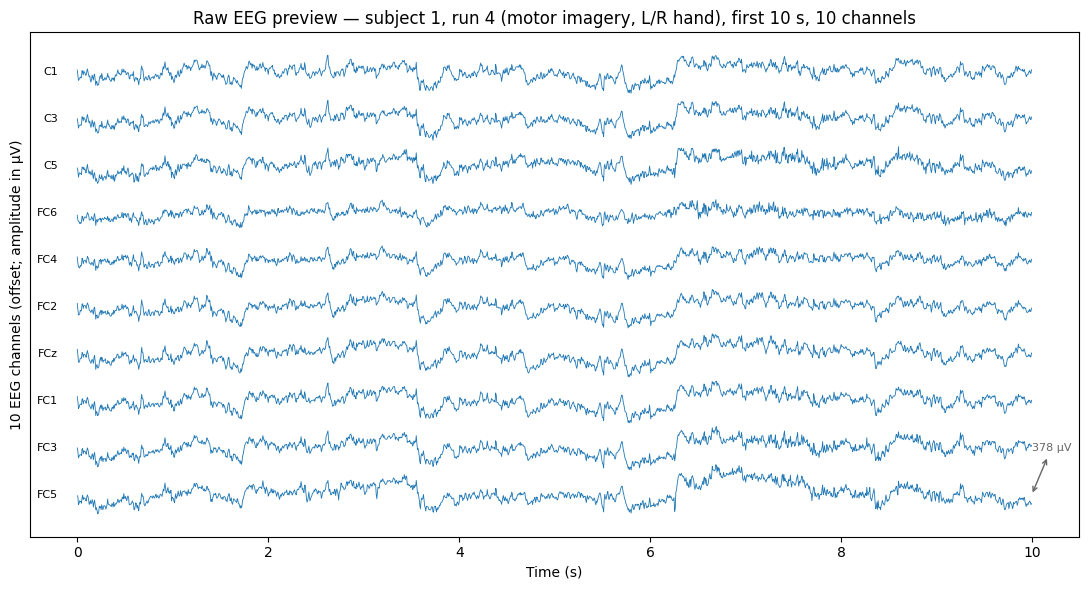

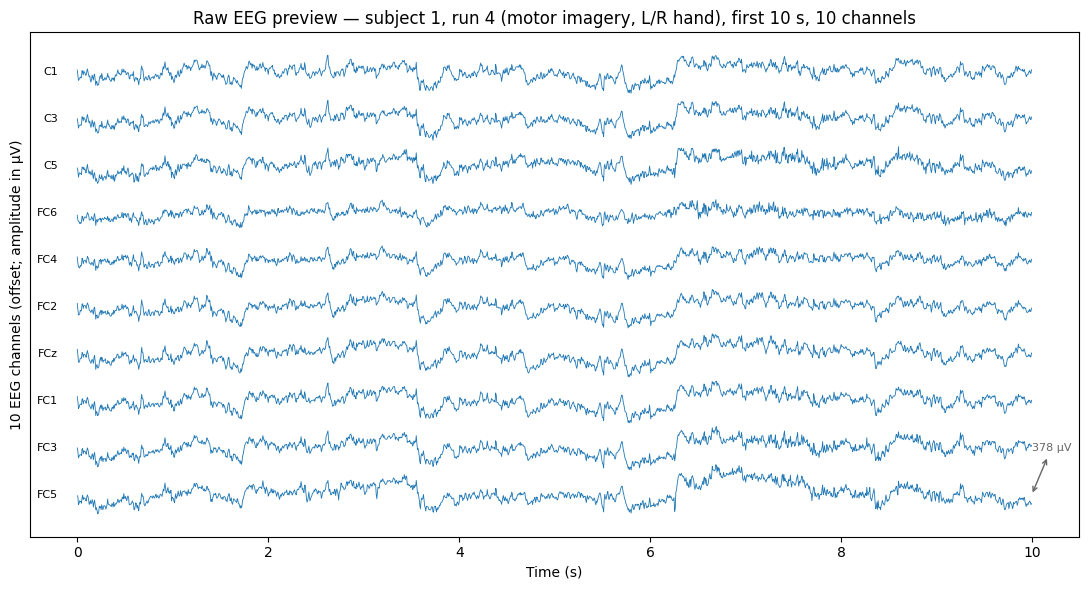

In [5]:
raw_s1r4 = data.load_raw(1, [4])
preprocessing.apply_montage(raw_s1r4)

fig_raw = visualization.plot_raw_preview(
    raw_s1r4,
    n_channels=10,
    duration=10.0,
    start=0.0,
    title="Raw EEG preview — subject 1, run 4 (motor imagery, L/R hand), first 10 s, 10 channels",
)
visualization.save_figure(fig_raw, FIGURES_DIR / "raw_signal_preview.png")
fig_raw

## 4 · Sensor / channel montage layout

We assign the standard **10-05 (`standard_1005`)** montage so the 64 electrodes
have known positions. This is required for the layout plot below and for any
future topographic summaries. The standardized EEGBCI names map cleanly onto the
montage.

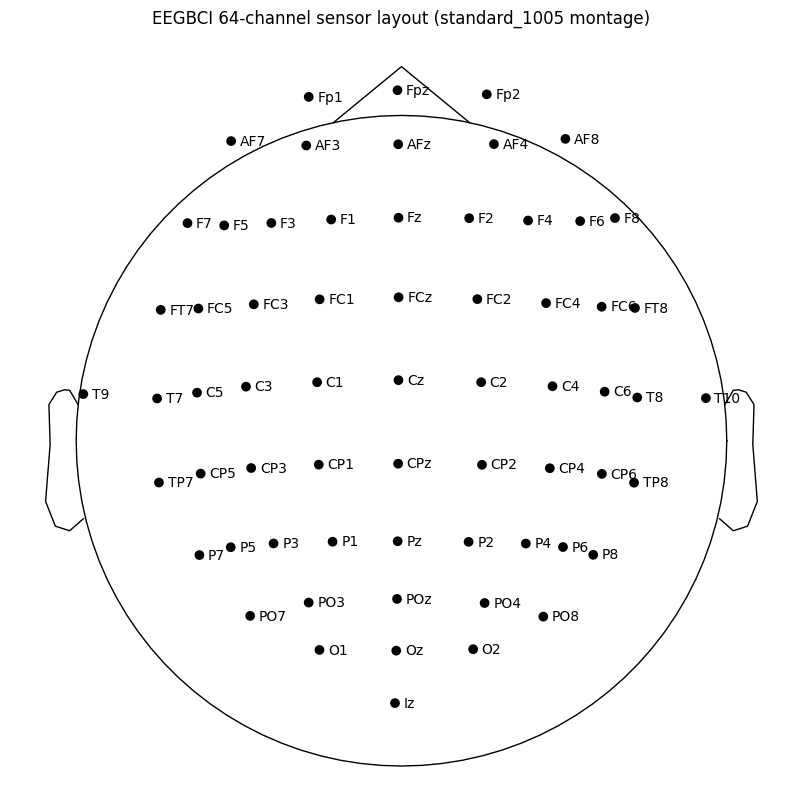

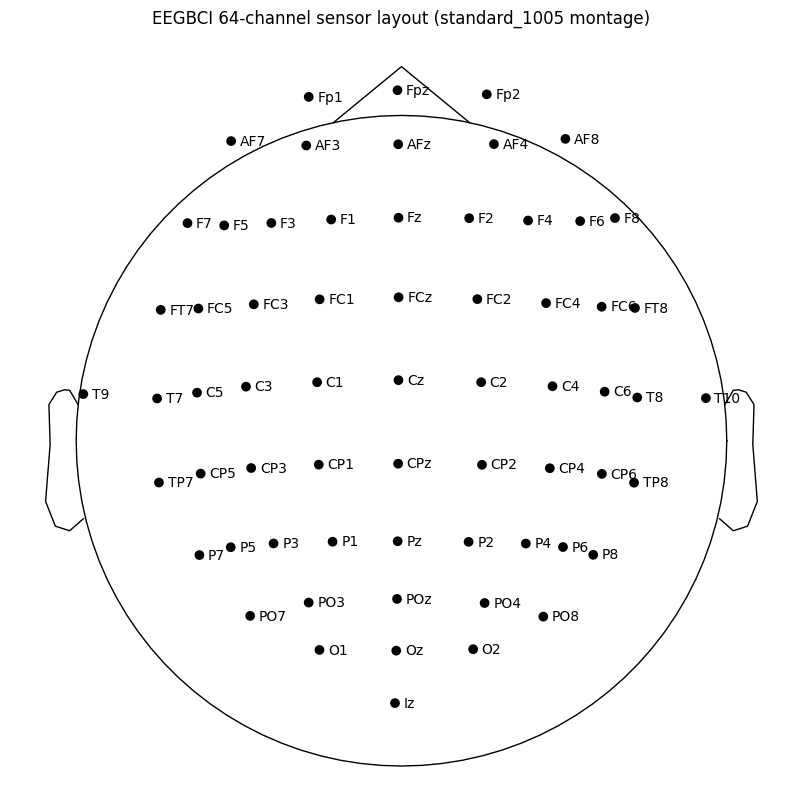

In [6]:
fig_montage = visualization.plot_channel_montage(
    raw_s1r4,
    title="EEGBCI 64-channel sensor layout (standard_1005 montage)",
)
visualization.save_figure(fig_montage, FIGURES_DIR / "channel_layout.png")
fig_montage

## 5 · Events / condition distribution

For every (subject, run) we read the annotations, map each code to its
**run-aware** condition, and count occurrences. Baseline runs contribute a
single continuous `T0` (rest) annotation each; the motor-imagery runs alternate
rest with left/right imagined-fist cues.

In [7]:
records = []
for subject, run in subject_runs:
    raw = data.load_run(subject, run, preload=False)
    mapping = config.map_events_by_run(run)
    for desc in raw.annotations.description:
        records.append(
            {
                "subject": subject,
                "run": run,
                "code": desc,
                "condition": mapping.get(desc, f"UNMAPPED:{desc}"),
            }
        )

events_long = pd.DataFrame(records)

# Per-condition totals across the whole v1 slice.
condition_counts = (
    events_long.groupby("condition").size().reset_index(name="count")
)
print("Event counts per condition (subjects 1–3, runs 1,2,4,8,12):")
condition_counts.sort_values("count", ascending=False, ignore_index=True)

Event counts per condition (subjects 1–3, runs 1,2,4,8,12):


,condition,count
0,rest,135
1,left fist (imagined),69
2,right fist (imagined),66
3,rest (eyes closed),3
4,rest (eyes open),3


In [8]:
# A more detailed breakdown by run and condition (tidy pivot).
breakdown = (
    events_long.groupby(["run", "condition"]).size().reset_index(name="count")
    .pivot(index="run", columns="condition", values="count")
    .fillna(0)
    .astype(int)
)
print("Event counts by run × condition (summed over subjects 1–3):")
breakdown

Event counts by run × condition (summed over subjects 1–3):


condition,left fist (imagined),rest,rest (eyes closed),rest (eyes open),right fist (imagined)
run,,,,,
1,0,0,0,3,0
2,0,0,3,0,0
4,23,45,0,0,22
8,23,45,0,0,22
12,23,45,0,0,22


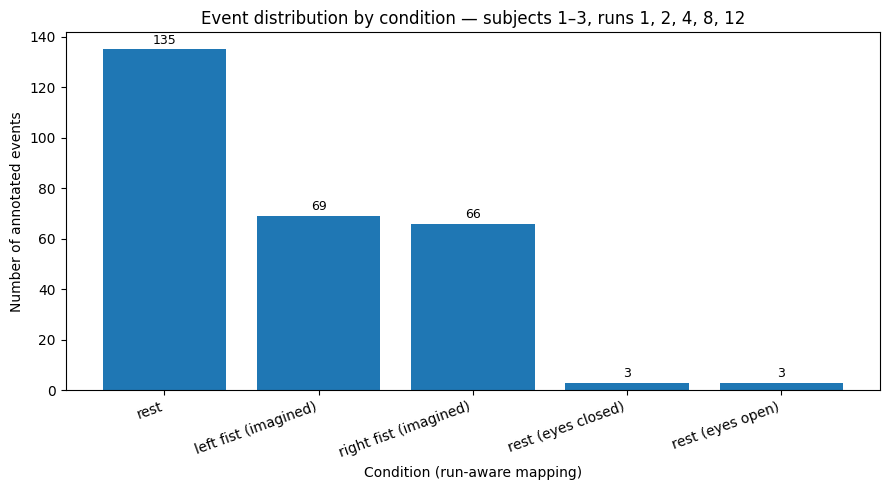

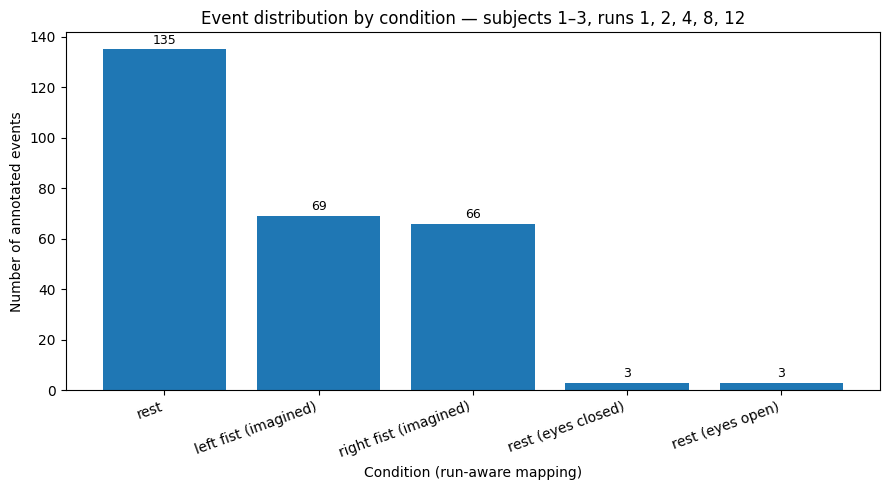

In [9]:
fig_events = visualization.plot_event_distribution(
    condition_counts,
    title="Event distribution by condition — subjects 1–3, runs 1, 2, 4, 8, 12",
)
visualization.save_figure(fig_events, FIGURES_DIR / "event_distribution.png")
fig_events

### Events timeline for one run

To make the rest/task structure concrete, here is the annotation timeline of a
single motor-imagery run (subject 1, run 4). Each bar is one annotation, placed
at its onset, with width equal to its duration and colored by the run-aware
condition. The alternation between rest and imagined left/right fist cues is
visible.

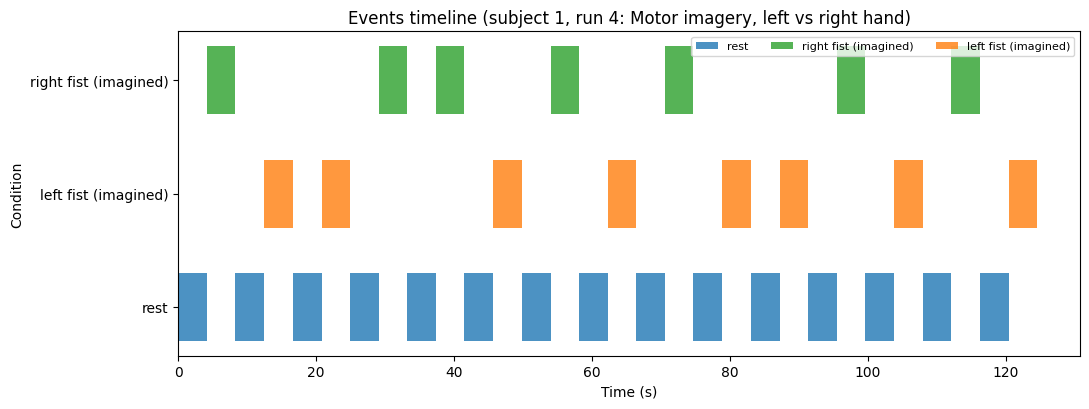

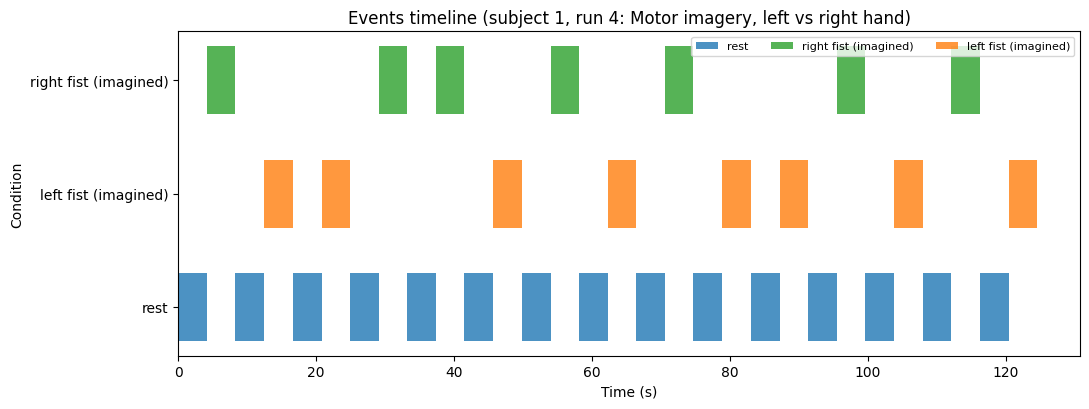

In [10]:
fig_timeline = visualization.plot_events_timeline(raw_s1r4, run=4, subject=1)
visualization.save_figure(fig_timeline, FIGURES_DIR / "events_timeline_subject1_run4.png")
fig_timeline

## What's next & limitations

**What this notebook established (Stages 2–3):**
- The selected slice loads reproducibly: **64 EEG channels, 160 Hz**, with
  per-run durations reported above.
- Annotation codes are mapped **by run type** (T0 = rest everywhere; T1/T2 =
  left/right imagined fist only in runs 4, 8, 12).
- First inspection figures were generated from real data and saved to
  `figures/`.

**Limitations (kept honest):**
- Only **3 subjects** and **5 runs** — not a representative sample of the full
  109-subject dataset. Nothing here generalizes beyond the selected data.
- The signal shown is **raw**: no filtering, referencing, or artifact handling
  has been applied, so the traces include drifts and likely ocular/movement
  artifacts.
- All notes are **descriptive only** — no clinical, diagnostic, or cognitive
  claims, and **no classifier** is built or implied.

**Recommended next step (Stages 4–5, → v0.3):**
1. Apply **conservative, documented preprocessing** (standard montage already
   set; add a gentle ~1–40 Hz band-pass, decide on an average reference, and
   inspect for line noise before any notch) with before/after evidence.
2. Build **events/epochs** from the run-aware mapping with a stated time window
   and event-count tables by subject/run/condition.
3. Compute a first **PSD baseline comparison** of eyes-open (run 1) vs
   eyes-closed (run 2), where an occipital alpha increase on eye closure is the
   expected, well-known sanity check.